# RehaPiano – klasifikátor zdravý / pacient z oboch testov (EXACT_FORCE + rytmus)

Pokračovanie úlohy *„Navrhnúť klasifikátor na oddelenie zdravých a chorých a ablačnú analýzu vplyvu jednotlivých faktorov
na výsledok klasifikácie"*. Hypotézy a normy podľa dekád sú pre každý test zvlášť:
- `notebooks/exact_force/statisticka_analyza_exact_force.ipynb` – 10 parametrov EXACT_FORCE (8 faktorov),
- `notebooks/rhythm/statisticka_analyza_rytmus.ipynb` – 10 parametrov rytmického testu (8 faktorov, M. Kuznietsov).

Tu oba testy **spojíme**: Pomôže druhý test k prvému? Ktorý test a ktoré faktory sú pre klasifikáciu najdôležitejšie?
Rovnaký postup ako v oboch notebookoch (logistická regresia a náhodný les, 5-násobná krížová validácia s 20 opakovaniami,
zdraví bez ťažkostí podľa dotazníka). Amplitúdy EXACT_FORCE sú v logaritme.

Kód: `src/rehapiano/combined.py`, `src/rehapiano/common/stats/group_analysis.py`, skript `scripts/run_combined_analysis.py`
(tabuľky v `outputs/combined/`). Celý projekt sa prepočíta príkazom `python scripts/run_all.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import roc_curve

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "rehapiano").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from rehapiano.common.config import COMBINED_OUTPUT_DIR as OUT

FIG = Path.cwd() / "figures" / "klasifikator_oba_testy"; FIG.mkdir(parents=True, exist_ok=True)
T = {path.stem: pd.read_csv(path) for path in sorted(OUT.glob("*.csv"))}
people = T["people"]
main = people.loc[people["screened"]]
N_H, N_P = int((main["group"] == "control").sum()), int((main["group"] == "patient").sum())
clf = T["classifier"]
MAIN_SET = clf["set"].iloc[0]

EF_COLOR, RH_COLOR, BOTH_COLOR = "#2a78d6", "#eb6834", "#1baf7a"
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "axes.titleweight": "bold", "axes.titlesize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10,
})


def fmt(value, digits=2):
    # Slovak decimal comma
    return f"{value:.{digits}f}".replace(".", ",")


def pval(p):
    return "< 0,001" if p < 0.001 else fmt(p, 3)


def color_of(name):
    return MUTED if name in ("vek", "len vek") else EF_COLOR if name.startswith(("EF", "EXACT")) else RH_COLOR


def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150); plt.show()


get = lambda feat, model="logistická regresia", s=MAIN_SET: clf.loc[
    (clf["set"] == s) & (clf["features"] == feat) & (clf["model"] == model)].iloc[0]
print(f"osoby s oboma testami: zdraví (bez ťažkostí) {N_H}, pacienti {N_P}")

osoby s oboma testami: zdraví (bez ťažkostí) 76, pacienti 48


## 1. Klasifikátor z jedného a z oboch testov

In [2]:
show = pd.DataFrame({
    "množina": clf["set"], "príznaky": clf["features"], "model": clf["model"], "osôb": clf["n_people"],
    "AUC": clf["auc"].map(fmt) + " [" + clf["auc_low"].map(fmt) + "–" + clf["auc_high"].map(fmt) + "]",
    "citlivosť": clf["sensitivity"].map(fmt), "špecificita": clf["specificity"].map(fmt),
    "vyvážená presnosť": clf["balanced_accuracy"].map(fmt)})
display(show)
perm = T["permutation_test"].iloc[0]
print(f"Permutačný test (logistická regresia, oba testy): AUC {fmt(perm['auc'])}, s pomiešanými skupinami priemer "
      f"{fmt(perm['null_mean'])} (97,5 % {fmt(perm['null_p97_5'])}), p = {pval(perm['p'])}")

,množina,príznaky,model,osôb,AUC,citlivosť,špecificita,vyvážená presnosť
0,76 zdravých + 48 pacientov,EXACT_FORCE,logistická regresia,124,"0,85 [0,83–0,86]","0,77","0,84","0,81"
1,76 zdravých + 48 pacientov,rytmus,logistická regresia,124,"0,85 [0,83–0,87]","0,76","0,83","0,79"
2,76 zdravých + 48 pacientov,EXACT_FORCE + rytmus,logistická regresia,124,"0,88 [0,86–0,90]","0,79","0,83","0,81"
3,76 zdravých + 48 pacientov,EXACT_FORCE + rytmus + vek,logistická regresia,124,"0,90 [0,89–0,92]","0,85","0,88","0,87"
4,76 zdravých + 48 pacientov,len vek,logistická regresia,124,"0,84 [0,83–0,85]","0,85","0,77","0,81"
5,76 zdravých + 48 pacientov,EXACT_FORCE,náhodný les,124,"0,88 [0,87–0,89]","0,80","0,82","0,81"
6,76 zdravých + 48 pacientov,rytmus,náhodný les,124,"0,82 [0,80–0,85]","0,70","0,85","0,77"
7,76 zdravých + 48 pacientov,EXACT_FORCE + rytmus,náhodný les,124,"0,91 [0,91–0,92]","0,84","0,86","0,85"
8,76 zdravých + 48 pacientov,EXACT_FORCE + rytmus + vek,náhodný les,124,"0,93 [0,92–0,93]","0,84","0,87","0,86"
9,76 zdravých + 48 pacientov,len vek,náhodný les,124,"0,80 [0,77–0,82]","0,78","0,76","0,77"


Permutačný test (logistická regresia, oba testy): AUC 0,88, s pomiešanými skupinami priemer 0,50 (97,5 % 0,64), p = 0,005


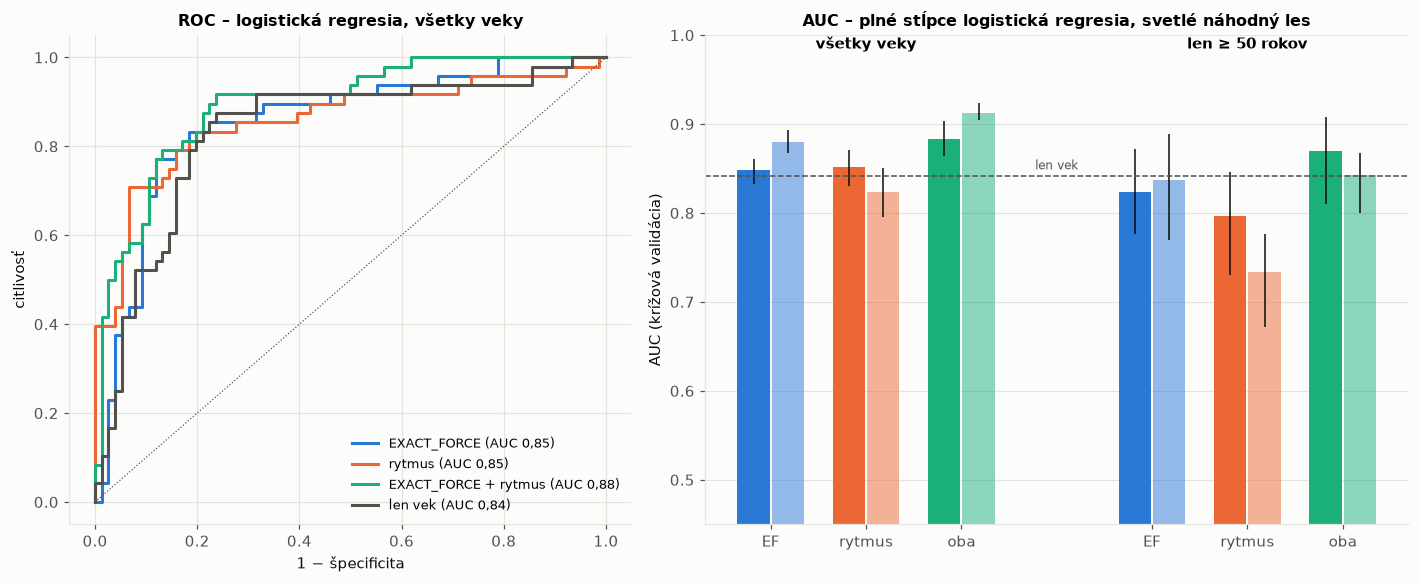

In [3]:
SETS = [("EXACT_FORCE", EF_COLOR), ("rytmus", RH_COLOR), ("EXACT_FORCE + rytmus", BOTH_COLOR), ("len vek", MUTED)]
oof = T["classifier_oof"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1, 1.25]})
for label, color in SETS:
    fpr, tpr, _ = roc_curve(oof["patient"], oof[f"logistická regresia | {label}"])
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{label} (AUC {fmt(get(label)['auc'])})")
axes[0].plot([0, 1], [0, 1], color=MUTED, lw=0.8, ls=":")
axes[0].set_xlabel("1 − špecificita"); axes[0].set_ylabel("citlivosť")
axes[0].set_title("ROC – logistická regresia, všetky veky"); axes[0].legend(loc="lower right", fontsize=8.5)

labels = ["EXACT_FORCE", "rytmus", "EXACT_FORCE + rytmus"]
older = f"{MAIN_SET}, len ≥ 50 rokov"
for j, (subset, title) in enumerate([(MAIN_SET, "všetky veky"), (older, "len ≥ 50 rokov")]):
    for i, label in enumerate(labels):
        for k, model in enumerate(["logistická regresia", "náhodný les"]):
            r = get(label, model, subset)
            x = j * 4 + i + (k - 0.5) * 0.36
            axes[1].bar(x, r["auc"], width=0.34, color=[EF_COLOR, RH_COLOR, BOTH_COLOR][i], alpha=1 if k == 0 else 0.5)
            axes[1].vlines(x, r["auc_low"], r["auc_high"], color=TEXT, lw=1)
axes[1].axhline(get("len vek")["auc"], color=MUTED, ls="--", lw=1)
axes[1].text(3, get("len vek")["auc"] + 0.008, "len vek", ha="center", fontsize=8, color=MUTED)
axes[1].set_xticks([0, 1, 2, 4, 5, 6], ["EF", "rytmus", "oba"] * 2)
for x, text in [(1, "všetky veky"), (5, "len ≥ 50 rokov")]:
    axes[1].text(x, 0.985, text, ha="center", fontsize=9.5, fontweight="bold")
axes[1].set_ylim(0.45, 1.0); axes[1].set_ylabel("AUC (krížová validácia)"); axes[1].grid(axis="x", visible=False)
axes[1].set_title("AUC – plné stĺpce logistická regresia, svetlé náhodný les")
save(fig, "01_klasifikator_oba_testy")

In [4]:
ef, rh, both, bothage, age = (get(n) for n in ["EXACT_FORCE", "rytmus", "EXACT_FORCE + rytmus", "EXACT_FORCE + rytmus + vek", "len vek"])
o_ef, o_rh, o_both = (get(n, s=older) for n in ["EXACT_FORCE", "rytmus", "EXACT_FORCE + rytmus"])
rf_both, rf_o_both = get("EXACT_FORCE + rytmus", "náhodný les"), get("EXACT_FORCE + rytmus", "náhodný les", older)
n50 = main.loc[main["age"] >= 50].groupby("group").size()
display(Markdown(f"""
**Záver 1:**
- Každý test sám oddelí pacientov približne rovnako dobre (logistická regresia: EXACT_FORCE AUC {fmt(ef["auc"])},
  rytmus {fmt(rh["auc"])}). **Oba testy spolu** dávajú AUC **{fmt(both["auc"])}** (náhodný les {fmt(rf_both["auc"])}),
  s vekom {fmt(bothage["auc"])}; samotný vek {fmt(age["auc"])}.
- **Rovnako starí (≥ 50 rokov, {n50.get("control", 0)} zdravých, {n50.get("patient", 0)} pacientov)**, kde vek skupiny
  takmer neodlišuje: EXACT_FORCE {fmt(o_ef["auc"])}, rytmus {fmt(o_rh["auc"])}, oba {fmt(o_both["auc"])}
  (náhodný les {fmt(rf_o_both["auc"])}). Testy sa tu **dopĺňajú** – každý zachytí trochu iných pacientov.
"""))


**Záver 1:**
- Každý test sám oddelí pacientov približne rovnako dobre (logistická regresia: EXACT_FORCE AUC 0,85,
  rytmus 0,85). **Oba testy spolu** dávajú AUC **0,88** (náhodný les 0,91),
  s vekom 0,90; samotný vek 0,84.
- **Rovnako starí (≥ 50 rokov, 17 zdravých, 40 pacientov)**, kde vek skupiny
  takmer neodlišuje: EXACT_FORCE 0,82, rytmus 0,80, oba 0,87
  (náhodný les 0,84). Testy sa tu **dopĺňajú** – každý zachytí trochu iných pacientov.


## 2. Ablačná analýza

**a) Testy ako celok** – čo stratíme, keď vynecháme celý test (alebo vek)?

In [5]:
ex = T["ablation_exercises"]
display(pd.DataFrame({"vynechaný faktor": ex["group"], "AUC všetko": ex["auc_all"].round(3),
                      "AUC bez neho": ex["auc_without"].round(3), "pokles AUC": ex["auc_drop"].round(3),
                      "AUC iba on": ex["auc_alone"].round(3)}).set_index("vynechaný faktor"))

,AUC všetko,AUC bez neho,pokles AUC,AUC iba on
vynechaný faktor,,,,
vek,0.905,0.883,0.022,0.841
RHYTHM,0.905,0.892,0.013,0.851
EXACT_FORCE,0.905,0.901,0.004,0.849


**b) Jednotlivé faktory oboch testov** (8 faktorov EXACT_FORCE + 8 faktorov rytmu): pokles AUC po vynechaní faktora
a AUC iba z faktora.

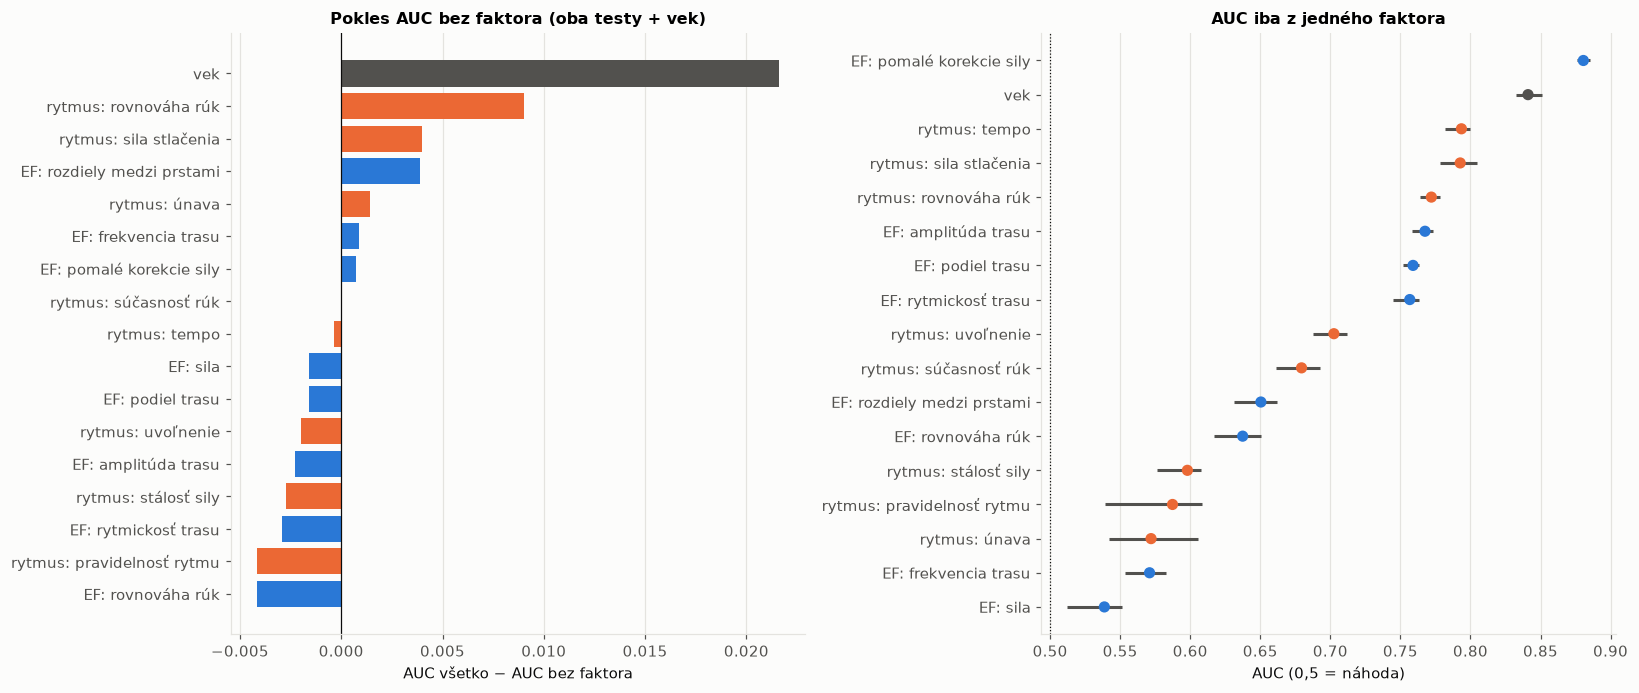

,AUC bez faktora,pokles AUC,AUC iba faktor
faktor (bez veku v modeli),,,
EF: pomalé korekcie sily,0.869,0.014,0.881
rytmus: rovnováha rúk,0.872,0.011,0.772
rytmus: súčasnosť rúk,0.882,0.001,0.679
rytmus: sila stlačenia,0.883,0.000,0.793
rytmus: tempo,0.884,-0.000,0.794
EF: frekvencia trasu,0.885,-0.002,0.571
EF: rovnováha rúk,0.886,-0.002,0.637
EF: podiel trasu,0.886,-0.003,0.759
EF: sila,0.886,-0.003,0.539


In [6]:
fac = T["ablation_factors_with_age"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4), sharey=False)
order = fac.sort_values("auc_drop")
axes[0].barh(order["group"], order["auc_drop"], color=[color_of(g) for g in order["group"]])
axes[0].axvline(0, color=TEXT, lw=0.8); axes[0].set_xlabel("AUC všetko − AUC bez faktora")
axes[0].set_title("Pokles AUC bez faktora (oba testy + vek)"); axes[0].grid(axis="y", visible=False)
alone = fac.sort_values("auc_alone")
axes[1].hlines(range(len(alone)), alone["auc_alone_low"], alone["auc_alone_high"], color=MUTED, lw=2)
axes[1].scatter(alone["auc_alone"], range(len(alone)), color=[color_of(g) for g in alone["group"]], s=40, zorder=3)
axes[1].set_yticks(range(len(alone)), alone["group"]); axes[1].axvline(0.5, color=TEXT, lw=0.8, ls=":")
axes[1].set_xlabel("AUC (0,5 = náhoda)"); axes[1].set_title("AUC iba z jedného faktora"); axes[1].grid(axis="y", visible=False)
save(fig, "02_ablacia_faktorov")

no_age = T["ablation_factors"]
display(pd.DataFrame({"faktor": no_age["group"], "AUC bez faktora": no_age["auc_without"].round(3),
                      "pokles AUC": no_age["auc_drop"].round(3), "AUC iba faktor": no_age["auc_alone"].round(3)})
        .set_index("faktor").rename_axis("faktor (bez veku v modeli)"))

In [7]:
top_alone = no_age.sort_values("auc_alone", ascending=False).head(4)
top_drop = no_age.head(3)
ex_i = ex.set_index("group")
display(Markdown(f"""
**Záver 2:**
- **Celé testy** (model oba testy + vek, AUC {fmt(ex_i.loc["vek", "auc_all"])}): bez EXACT_FORCE klesne AUC o {fmt(ex_i.loc["EXACT_FORCE", "auc_drop"], 3)}, bez rytmu o
  {fmt(ex_i.loc["RHYTHM", "auc_drop"], 3)}, bez veku o {fmt(ex_i.loc["vek", "auc_drop"], 3)}. Rytmus teda
  pridáva k EXACT_FORCE viac než naopak, hoci samy osebe sú oba testy rovnako silné.
- **Najsilnejšie faktory samy osebe:** {", ".join(f"{r.group} (AUC {fmt(r.auc_alone)})" for r in top_alone.itertuples())}.
- **Najväčší pokles po vynechaní:** {", ".join(f"{r.group} ({fmt(r.auc_drop, 3)})" for r in top_drop.itertuples())}.
  Poklesy sú malé – faktory sa navzájom zastupujú, a to aj medzi testami.
"""))


**Záver 2:**
- **Celé testy** (model oba testy + vek, AUC 0,90): bez EXACT_FORCE klesne AUC o 0,004, bez rytmu o
  0,013, bez veku o 0,022. Rytmus teda
  pridáva k EXACT_FORCE viac než naopak, hoci samy osebe sú oba testy rovnako silné.
- **Najsilnejšie faktory samy osebe:** EF: pomalé korekcie sily (AUC 0,88), rytmus: tempo (AUC 0,79), rytmus: sila stlačenia (AUC 0,79), rytmus: rovnováha rúk (AUC 0,77).
- **Najväčší pokles po vynechaní:** EF: pomalé korekcie sily (0,014), rytmus: rovnováha rúk (0,011), rytmus: súčasnosť rúk (0,001).
  Poklesy sú malé – faktory sa navzájom zastupujú, a to aj medzi testami.


In [8]:
display(Markdown(f"""
## Zhrnutie

- EXACT_FORCE a rytmický test oddeľujú zdravých a pacientov podobne dobre (AUC {fmt(ef["auc"])} a {fmt(rh["auc"])});
  spolu {fmt(both["auc"])}, u osôb ≥ 50 rokov {fmt(o_both["auc"])} (každý test sám {fmt(o_ef["auc"])} / {fmt(o_rh["auc"])}).
- Najviac informácie nesú pomalé korekcie sily v EXACT_FORCE a tempo a rovnováha rúk v rytmickom teste; ostatné faktory
  sa s nimi prekrývajú.
- **Obmedzenia:** zdraví a pacienti hrali inú verziu hier (iné `step_id`), pacienti sú výrazne starší a zdravých nad
  50 rokov je málo; klasifikátor nie je overený na nezávislých dátach – nejde o diagnostický nástroj.
"""))


## Zhrnutie

- EXACT_FORCE a rytmický test oddeľujú zdravých a pacientov podobne dobre (AUC 0,85 a 0,85);
  spolu 0,88, u osôb ≥ 50 rokov 0,87 (každý test sám 0,82 / 0,80).
- Najviac informácie nesú pomalé korekcie sily v EXACT_FORCE a tempo a rovnováha rúk v rytmickom teste; ostatné faktory
  sa s nimi prekrývajú.
- **Obmedzenia:** zdraví a pacienti hrali inú verziu hier (iné `step_id`), pacienti sú výrazne starší a zdravých nad
  50 rokov je málo; klasifikátor nie je overený na nezávislých dátach – nejde o diagnostický nástroj.
